In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
from scipy.stats import norm
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go

**load data**

In [9]:
# saving only the added delta values and biosample/DHS inds
# for i in range(1, 2):
#     print(i)
#     #load npz file
#     filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
#     cycle_np_file = np.load(filename)
    
#     biosample_inds_to_1 = cycle_np_file['biosample_inds_to_1']
#     DHS_inds_to_1 = cycle_np_file['DHS_inds_to_1']
#     biosample_inds_to_0 = cycle_np_file['biosample_inds_to_0']
#     DHS_inds_to_0 = cycle_np_file['DHS_inds_to_0']
    
#     dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
#     n_biosample, n_DHSs = dhs_arr.shape
#     dhs_arr_flat = dhs_arr.flatten()
#     del dhs_arr
    
    
#     inds_to_0 = np.int64(DHS_inds_to_0) + (n_DHSs * np.int64(biosample_inds_to_0))
#     inds_to_1 = np.int64(DHS_inds_to_1) + (n_DHSs * np.int64(biosample_inds_to_1))
    
#     filtered_added_flat_inds_all_cycles = inds_to_1[~dhs_arr_flat[inds_to_1]]
#     filtered_removed_flat_inds_all_cycles = inds_to_0[dhs_arr_flat[inds_to_0]]
#     del dhs_arr_flat
    
#     recon_flat_array = cycle_np_file['recon_flat_array']
    
#     #in order of first removed and first added to last removed and last added
#     sorted_inds_to_0 = filtered_removed_flat_inds_all_cycles[np.argsort(recon_flat_array[filtered_removed_flat_inds_all_cycles])]
#     sorted_inds_to_1 = filtered_added_flat_inds_all_cycles[np.argsort(-recon_flat_array[filtered_added_flat_inds_all_cycles])]
    
#     #corresponding delta vals
#     sorted_recon_removed = recon_flat_array[sorted_inds_to_0]
#     sorted_recon_added = recon_flat_array[sorted_inds_to_1]
    
#     del recon_flat_array
    
#     #save
#     new_filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
#     np.savez(new_filename, added_recon=sorted_recon_added, removed_recon=sorted_recon_removed, added_flat_inds=sorted_inds_to_1, removed_flat_inds=sorted_inds_to_0)

1


In [2]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [3]:
len(added_recon_all_cycles[0])

46842

In [4]:
len(removed_recon_all_cycles[0])

22450

In [3]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [4]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [5]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

**Remaining Call Max signal**

In [10]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
np_file = np.load(filename)
cycle1_dhs_arr = np_file['new_dhs_array']

In [11]:
del DHS_peak_signal_array

In [12]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
max_DHS_signal_array = np.load(file)

In [13]:
cycle1_remaining_calls_max_signal_arr = max_DHS_signal_array[cycle1_dhs_arr]
print(np.mean(cycle1_remaining_calls_max_signal_arr))

1.969459891994696


In [14]:
cycle0_remaining_calls_max_signal_arr = max_DHS_signal_array[cycle0_dhs_arr]
print(np.mean(cycle0_remaining_calls_max_signal_arr))

1.9696631816034942


**Precision with lower end delta values**

In [2]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-1.0_to1thresh1.0_cycle1_CT20220321.npz'
cycle_np_file = np.load(filename)
diff_flat_array = cycle_np_file['diff_flat_array']

In [20]:
thresholds = [-0.9, -0.99, -0.999, -0.9999, -0.99999, -0.999999, -0.9999999, -0.99999999, -0.999999999, -0.9999999999]
num_deltas_below_thresh = []
for thresh in thresholds:
    num_deltas_below_thresh.append(len(diff_flat_array[diff_flat_array<=thresh]))

In [19]:
len(np.where(diff_flat_array==-1)[0])

22464

In [17]:
diff_flat_array[61585]

-1.0

In [26]:
(diff_flat_array<-0.9999999)[61585]

True

In [21]:
num_deltas_below_thresh

[8607178, 759840, 47087, 25800, 22962, 22547, 22478, 22464, 22464, 22464]

In [29]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
cycle_np_file = np.load(filename)
recon_flat_array = cycle_np_file['recon_flat_array']

In [38]:
len(np.where(recon_flat_array==0)[0])

791817981

In [44]:
thresholds = [0.1, 0.01, 0.001, 0.0001, 0.00001, 0.000001, 0.0000001, 
              0.00000001, 0.000000001, 0.0000000001, 0.00000000001, 
              0.000000000001, 0.0000000000001, 0.00000000000001]
num_recons_below_thresh = []
for thresh in thresholds:
    num_recons_below_thresh.append(len(recon_flat_array[recon_flat_array<=thresh]))

In [46]:
num_recons_below_thresh = np.array(num_recons_below_thresh)
num_recons_below_thresh

array([2452110203, 2015128253, 1299540529,  926389248,  821734675,
        796439210,  792514891,  791896455,  791821731,  791818254,
        791818008,  791817983,  791817981,  791817981])

**Reconstruction values over cycles**

In [11]:
all_cycles_recon_mean = []
all_cycles_recon_std = []
for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_reconflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    diff_flat_array = cycle_np_file['recon_flat_array']
    
    cycle_recon_mean = np.mean(diff_flat_array)
    all_cycles_recon_mean.append(cycle_recon_mean)
    
    cycle_recon_std = np.std(diff_flat_array)
    all_cycles_recon_std.append(cycle_recon_std)
    
    del diff_flat_array
    
all_cycles_recon_mean = np.array(all_cycles_recon_mean)
all_cycles_recon_std = np.array(all_cycles_recon_std)

1


In [12]:
ci_95 = []
for i in range(1):
    ci_95.append(norm.interval(0.95, loc=all_cycles_recon_mean[i], scale=all_cycles_recon_std[i]/np.sqrt(n_DHSs*733)))
ci_95 = np.array(ci_95)

Text(0.5, 1.0, 'Reconstruction Values for All Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=0.0/1.0')

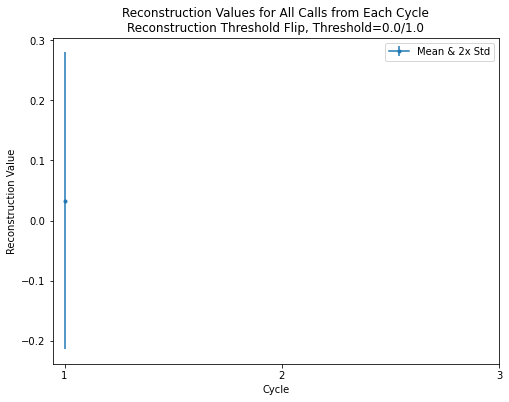

In [15]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.errorbar(np.arange(1, 2), all_cycles_recon_mean, all_cycles_recon_std*2, marker='.')

plt.xticks([1, 2, 3])
plt.legend(['Mean & 2x Std'])
# plt.yscale('symlog')
plt.xlabel('Cycle')
plt.ylabel('Reconstruction Value')
plt.title('Reconstruction Values for All Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=0.0/1.0')

Text(0.5, 1.0, 'Reconstruction Values for Removed Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=0.0/1.0')

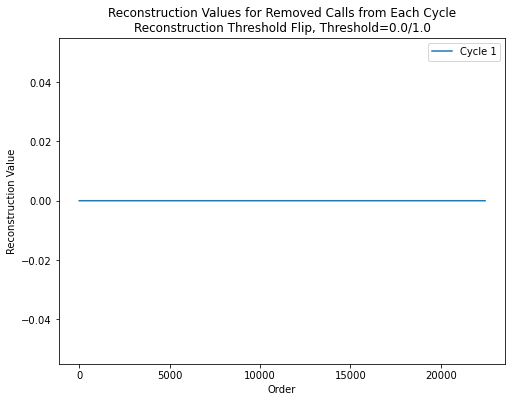

In [16]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.plot(np.arange(len(removed_recon_all_cycles[i])), removed_recon_all_cycles[i])

plt.legend(['Cycle 1'])
# plt.yticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
# plt.yscale('symlog')
# plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Order')
plt.ylabel('Reconstruction Value')
plt.title('Reconstruction Values for Removed Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=0.0/1.0')

Text(0.5, 1.0, 'Reconstruction Values for Added (Previously 0) Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=-1.0/1.0')

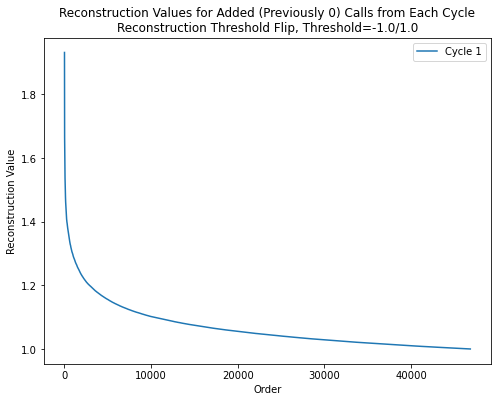

In [18]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.plot(np.arange(len(added_recon_all_cycles[i])), added_recon_all_cycles[i])

plt.legend(['Cycle 1'])
# plt.yticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
# plt.yscale('symlog')
# plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Order')
plt.ylabel('Reconstruction Value')
plt.title('Reconstruction Values for Added (Previously 0) Calls from Each Cycle\nReconstruction Threshold Flip, Threshold=-1.0/1.0')

**Plotting delta vs peak signal and peak signal vs mean signal for added and removed calls**

In [19]:
#finding peak signal values of added calls
removed_peak_signal_all_cycles = []
for i in range(1):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0


Text(0.5, 1.0, 'Comparing Reconstruction Values to DHS Peak Signal for Removed Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

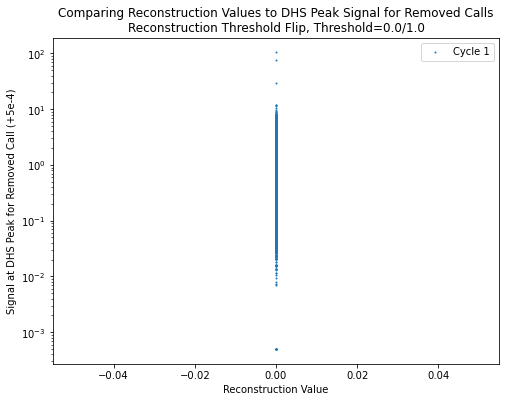

In [20]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.scatter(removed_recon_all_cycles[i], removed_peak_signal_all_cycles[i]+0.0005, s=1)

# plt.xlim([1.2, 2])
# plt.ylim([0.0004, 110])
plt.yscale('log')
plt.legend(['Cycle 1'])
plt.xlabel('Reconstruction Value')
plt.ylabel('Signal at DHS Peak for Removed Call (+5e-4)')
plt.title('Comparing Reconstruction Values to DHS Peak Signal for Removed Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

In [21]:
#finding peak signal values of added calls
added_peak_signal_all_cycles = []
for i in range(1):
    print(i)
    added_peak_signal_single_cycle = []
    for biosample, dhs in zip((added_flat_inds_all_cycles[i] // n_DHSs), (added_flat_inds_all_cycles[i] % n_DHSs)):
        added_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    added_peak_signal_single_cycle = np.array(added_peak_signal_single_cycle)
    added_peak_signal_all_cycles.append(added_peak_signal_single_cycle)

0


Text(0.5, 1.0, 'Comparing Reconstruction Values to DHS Peak Signal for Added Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

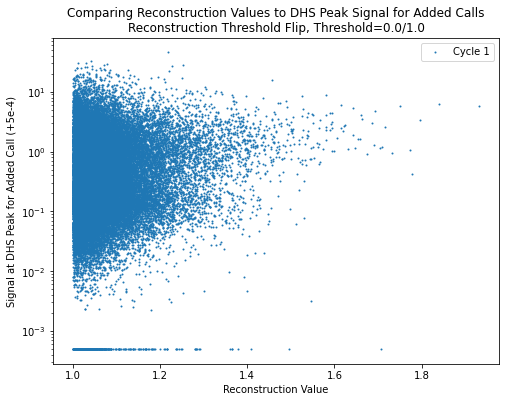

In [23]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.scatter(added_recon_all_cycles[i], added_peak_signal_all_cycles[i]+0.0005, s=1)
#     plt.xlim([1.2, 2])
#     plt.ylim([0.0004, 110])

plt.yscale('log')
plt.legend(['Cycle 1'])

plt.xlabel('Reconstruction Value')
plt.ylabel('Signal at DHS Peak for Added Call (+5e-4)')
plt.title('Comparing Reconstruction Values to DHS Peak Signal for Added Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

In [24]:
#finding average signal value of DHS of removed calls
removed_mean_signal_all_cycles = []
for i in range(1):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(removed_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    removed_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [25]:
#finding average signal value of DHS of added calls
added_mean_signal_all_cycles = []
for i in range(1):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(added_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    added_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [26]:
for i in removed_mean_signal_all_cycles:
    print(np.max(i))
    print(np.min(i))

14.8228905357143
0.0726483333333333


Text(0.5, 1.08, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nReconstruction Threshold Flip, Threshold=0.0/1.0')

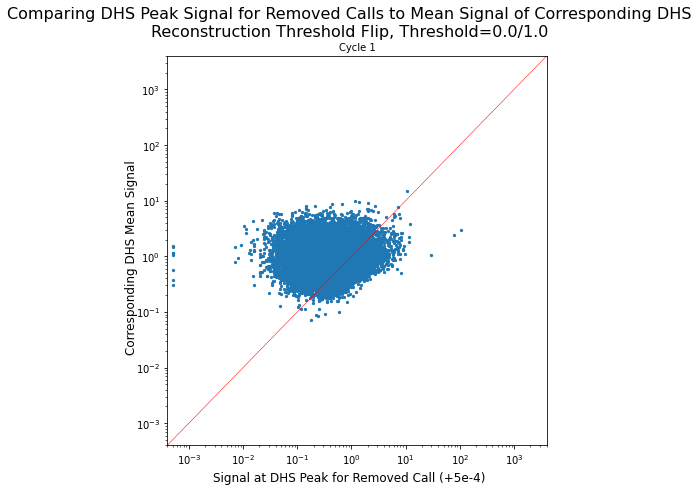

In [28]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6,6))
fig.patch.set_facecolor('white')
fig.tight_layout()

scat = axes.scatter(removed_peak_signal_all_cycles[0]+0.0005, removed_mean_signal_all_cycles[0], s=5)
axes.set_title('Cycle 1', fontsize=10)
axes.set_xlim([0.0004, 4000])
axes.set_ylim([0.0004, 4000])
axes.set_xscale('log')
axes.set_yscale('log')
axes.plot(np.arange(5000)-1, np.arange(5000)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.08)

Text(0.5, 1.08, 'Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nReconstruction Threshold Flip, Threshold=0.0/1.0')

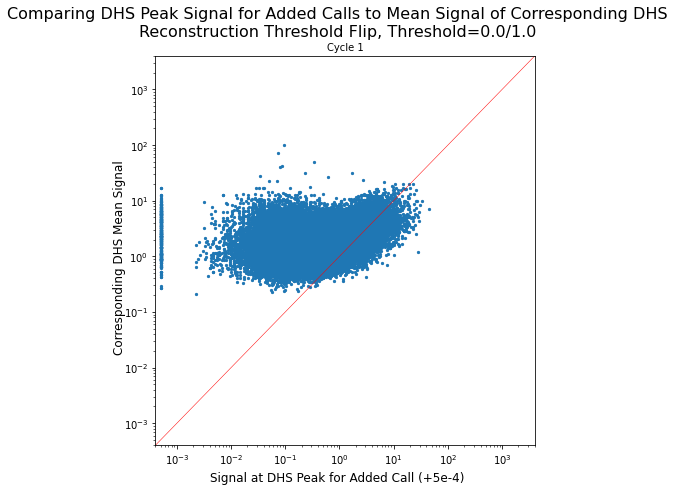

In [36]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6,6))
fig.patch.set_facecolor('white')
fig.tight_layout()


scat = axes.scatter(added_peak_signal_all_cycles[0]+0.0005, added_mean_signal_all_cycles[0], s=5)
axes.set_title('Cycle 1', fontsize=10)
axes.set_xlim([0.0004, 4000])
axes.set_ylim([0.0004, 4000])
axes.set_xscale('log')
axes.set_yscale('log')
axes.plot(np.arange(5000)-1, np.arange(5000)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.08)

In [30]:
added_peak_signal_all_cycles_counts = []
b = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
for c in range(1):
    data = added_peak_signal_all_cycles[c]
    cycle_count = []
    for i in range(len(b)-1):
        cycle_count.append(len(data[(data>=b[i]) & (data<b[i+1])]))
    cycle_count = cycle_count/np.sum(cycle_count)
    added_peak_signal_all_cycles_counts.append(np.array(cycle_count))

In [31]:
removed_peak_signal_all_cycles_counts = []
b = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
for c in range(1):
    data = removed_peak_signal_all_cycles[c]
    cycle_count = []
    for i in range(len(b)-1):
        cycle_count.append(len(data[(data>=b[i]) & (data<b[i+1])]))
    cycle_count = cycle_count/np.sum(cycle_count)
    removed_peak_signal_all_cycles_counts.append(np.array(cycle_count))

Text(0.5, 1.07, 'Peak Signal for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

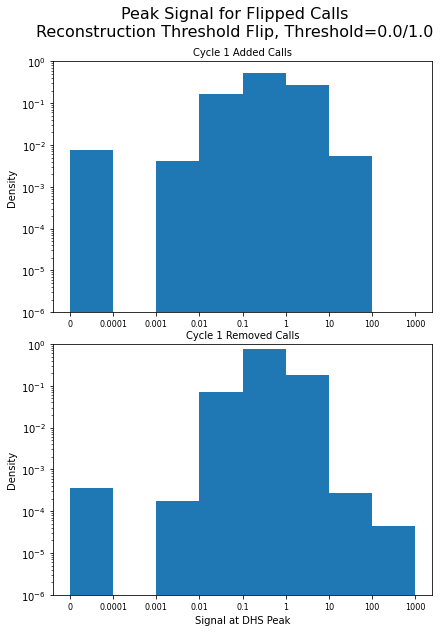

In [34]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(1):
    axes[ind].bar(np.arange(len(added_peak_signal_all_cycles_counts[ind])), 
                  added_peak_signal_all_cycles_counts[ind], 
                  align='edge',
                  width=1)
    axes[ind+1].bar(np.arange(len(removed_peak_signal_all_cycles_counts[ind])), 
                    removed_peak_signal_all_cycles_counts[ind], 
                    align='edge',
                    width=1)
    axes[ind].set_title('Cycle %s Added Calls' %(ind+1), fontsize=10)
    axes[ind+1].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
    axes[ind].set_yscale('log')
    axes[ind+1].set_yscale('log')
    
    axes[ind].set_ylim([1e-6, 1])
    axes[ind+1].set_ylim([1e-6, 1])
    
#     axes[ind].set_xscale('log')
#     axes[ind+3].set_xscale('log')
    
    axes[ind].set_xticks(np.arange(len(added_peak_signal_all_cycles_counts[ind])+1))
    axes[ind+1].set_xticks(np.arange(len(removed_peak_signal_all_cycles_counts[ind])+1))
    axes[ind].set_xticklabels(['0', '0.0001', '0.001', '0.01', '0.1', '1', '10', '100', '1000'], fontsize=8)
    axes[ind+1].set_xticklabels(['0', '0.0001', '0.001', '0.01', '0.1', '1', '10', '100', '1000'], fontsize=8)
    
axes[1].set_xlabel('Signal at DHS Peak')
axes[0].set_ylabel('Density')
axes[1].set_ylabel('Density')
plt.suptitle('Peak Signal for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Peak Signal for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

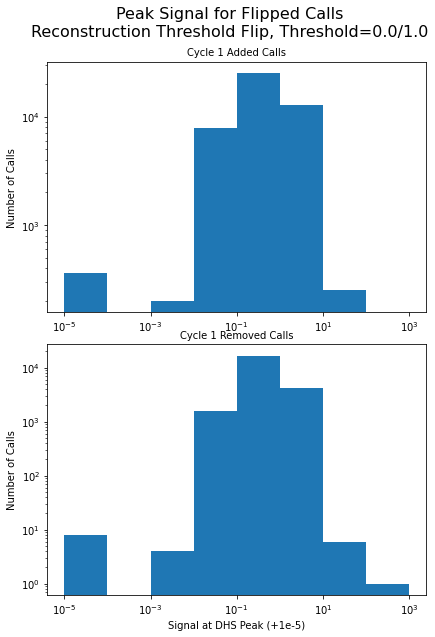

In [35]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

b = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

axes = axes.ravel()
for ind in range(1):
    axes[ind].hist(added_peak_signal_all_cycles[ind]+0.00001, bins=b)
    axes[ind+1].hist(removed_peak_signal_all_cycles[ind]+0.00001, bins=b)
    axes[ind].set_title('Cycle %s Added Calls' %(ind+1), fontsize=10)
    axes[ind+1].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
    axes[ind].set_yscale('log')
    axes[ind+1].set_yscale('log')
    
#     axes[ind].set_ylim([10, 1e8])
#     axes[ind+1].set_ylim([10, 1e8])
    
    axes[ind].set_xscale('log')
    axes[ind+1].set_xscale('log')
    
    axes[ind].set_xticks(b[::2])
    axes[ind+1].set_xticks(b[::2])
#     axes[ind].set_xticklabels([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3], fontsize=8)
#     axes[ind+3].set_xticklabels([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3], fontsize=8)
    
axes[1].set_xlabel('Signal at DHS Peak (+1e-5)')
axes[0].set_ylabel('Number of Calls')
axes[1].set_ylabel('Number of Calls')
plt.suptitle('Peak Signal for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

**Biosample SPOT Scores**

In [37]:
#how many biosamples have call changes in 10 cycles
changed_biosamples = set()
for i in range(1):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    for j in biosample_inds:
        changed_biosamples.add(j)
len(changed_biosamples)

647

In [38]:
added_biosample_spot_scores_all_cycles = []
for i in range(1):
    biosample_inds = added_flat_inds_all_cycles[i] // n_DHSs
    added_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

In [39]:
removed_biosample_spot_scores_all_cycles = []
for i in range(1):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    removed_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

Text(0.5, 1.0, 'Comparing Reconstruction Values to Corresponding Biosample SPOT Scores for Added Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

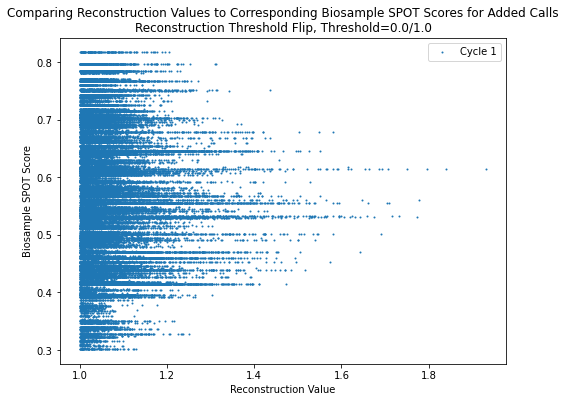

In [41]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.scatter(added_recon_all_cycles[i], added_biosample_spot_scores_all_cycles[i], s=1)
#     plt.xlim([1.2, 2])
#     plt.ylim([0.3, 0.8])
    
plt.legend(['Cycle 1'])

plt.xlabel('Reconstruction Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Reconstruction Values to Corresponding Biosample SPOT Scores for Added Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

Text(0.5, 1.0, 'Comparing Reconstruction Values to Corresponding Biosample SPOT Scores for Removed Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

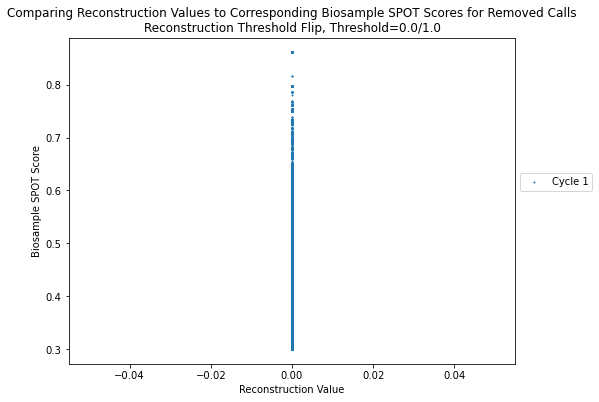

In [42]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(1):
    plt.scatter(removed_recon_all_cycles[i], removed_biosample_spot_scores_all_cycles[i], s=1)
#     plt.xlim([1.2, 2])
    
plt.legend(['Cycle 1'], loc=(1.01, 0.53))
plt.xlabel('Reconstruction Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Reconstruction Values to Corresponding Biosample SPOT Scores for Removed Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

In [43]:
for i in range(1):
    print(np.mean(added_biosample_spot_scores_all_cycles[i]))
    
for i in range(1):
    print(np.mean(removed_biosample_spot_scores_all_cycles[i]))

0.5714298834379403
0.4820141737193764


Text(0.5, 1.07, 'SPOT Scores for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

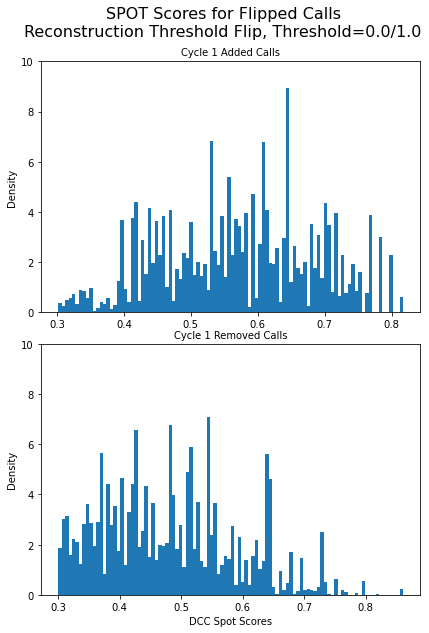

In [48]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(1):
    axes[ind].hist(added_biosample_spot_scores_all_cycles[ind], bins=100, density=True)
    axes[ind+1].hist(removed_biosample_spot_scores_all_cycles[ind], bins=100, density=True)
    axes[ind].set_title('Cycle %s Added Calls' %(ind+1), fontsize=10)
    axes[ind+1].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
    axes[ind].set_ylim([0, 10])
    axes[ind+1].set_ylim([0, 10])
    
axes[1].set_xlabel('DCC Spot Scores')
axes[0].set_ylabel('Density')
axes[1].set_ylabel('Density')
plt.suptitle('SPOT Scores for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'SPOT Scores for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0')

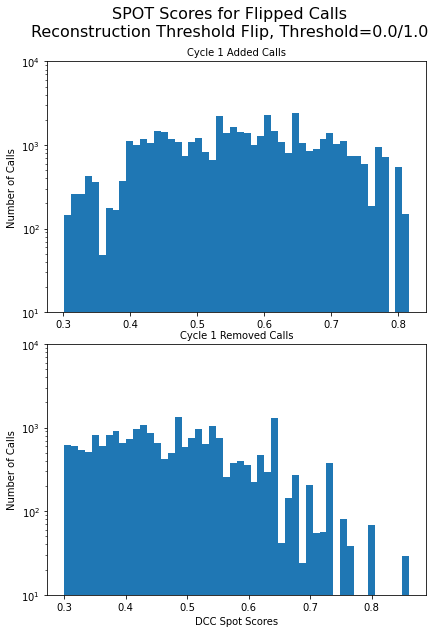

In [47]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(1):
    axes[ind].hist(added_biosample_spot_scores_all_cycles[ind], bins=50)
    axes[ind+1].hist(removed_biosample_spot_scores_all_cycles[ind], bins=50)
    axes[ind].set_title('Cycle %s Added Calls' %(ind+1), fontsize=10)
    axes[ind+1].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
#     axes[ind].set_ylim([0, 250000])
#     axes[ind+3].set_ylim([0, 1200000])
#     axes[ind].set_ylim([0, 13])
#     axes[ind+3].set_ylim([0, 13])
    axes[ind].set_yscale('log')
    axes[ind+1].set_yscale('log')
    axes[ind].set_ylim([10, 1e4])
    axes[ind+1].set_ylim([10, 1e4])
    
axes[1].set_xlabel('DCC Spot Scores')
axes[0].set_ylabel('Number of Calls')
axes[1].set_ylabel('Number of Calls')
plt.suptitle('SPOT Scores for Flipped Calls\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)